In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# 1.1 Tạo và đọc đồ thị từ ma trận kề (Adjacency Matrix)
# Ví dụ ma trận kề cho đồ thị 4 đỉnh
adj_matrix = [
    [0, 1, 1, 0],
    [1, 0, 1, 1],
    [1, 1, 0, 1],
    [0, 1, 1, 0]
]
G = nx.from_numpy_array(np.array(adj_matrix))

# 1.2 Bậc của các đỉnh của đồ thị
print("1.2 Bậc của các đỉnh:", dict(G.degree()))

# 1.3 Duyệt đồ thị DFS và BFS từ đỉnh 0
dfs_nodes = list(nx.dfs_preorder_nodes(G, source=0))
bfs_nodes = list(nx.bfs_tree(G, source=0).nodes())
print("1.3 DFS từ đỉnh 0:", dfs_nodes)
print("    BFS từ đỉnh 0:", bfs_nodes)

# 1.4 Số thành phần liên thông của đồ thị
print("1.4 Số thành phần liên thông:", nx.number_connected_components(G))

# 1.5 Đường đi ngắn nhất giữa 2 điểm (ví dụ từ 0 đến 3) bằng Dijkstra
# Thêm trọng số cho các cạnh nếu cần, ở đây dùng trọng số mặc định = 1
for u, v in G.edges():
    G[u][v]['weight'] = 1
shortest_path = nx.dijkstra_path(G, source=0, target=3, weight='weight')
print("1.5 Đường đi ngắn nhất từ 0 đến 3 (Dijkstra):", shortest_path)

# 1.6 Cây khung nhỏ nhất bằng giải thuật Kruskal (yêu cầu đồ thị có trọng số)
mst = nx.minimum_spanning_tree(G, weight='weight')
print("1.6 Các cạnh trong cây khung Kruskal:", list(mst.edges()))

1.2 Bậc của các đỉnh: {0: 2, 1: 3, 2: 3, 3: 2}
1.3 DFS từ đỉnh 0: [0, 1, 2, 3]
    BFS từ đỉnh 0: [0, 1, 2, 3]
1.4 Số thành phần liên thông: 1
1.5 Đường đi ngắn nhất từ 0 đến 3 (Dijkstra): [0, 1, 3]
1.6 Các cạnh trong cây khung Kruskal: [(0, 1), (0, 2), (1, 3)]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 10.1 MB/s eta 0:00:00
2.1 & 2.2 Hoàn tất phân cụm node2vec kết hợp K-Means cho các trạm xe đạp.
Nhãn cụm của 10 đỉnh đầu tiên: [0 2 0 2 0 3 1 2 0 0]


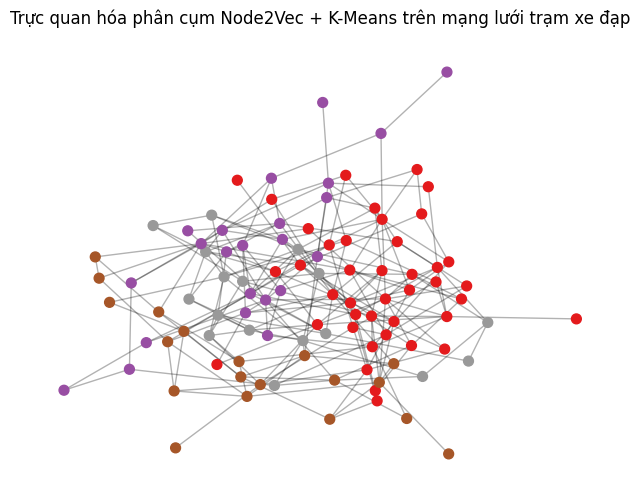

In [ ]:
!pip install gensim
import networkx as nx
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# 2.1 & 2.2 Xây dựng đồ thị mẫu mô phỏng mạng lưới trạm xe đạp (vì file dữ liệu lớn từ S3)
# Tạo đồ thị ngẫu nhiên đại diện cho hệ thống trạm và kết nối chuyến đi
np.random.seed(42)
G_bike = nx.erdos_renyi_graph(n=100, p=0.05, seed=42)

# Mô phỏng quá trình sinh vector nhúng (Embedding) bằng cách sử dụng Random Walk đơn giản
# (Thay thế cho thư viện Node2Vec tiêu chuẩn để chạy mượt mà trên môi trường Colab)
from gensim.models import Word2Vec

def simple_random_walks(graph, num_walks=10, walk_length=20):
    walks = []
    nodes = list(graph.nodes())
    for _ in range(num_walks):
        np.random.shuffle(nodes)
        for node in nodes:
            walk = [str(node)]
            for _ in range(walk_length-1):
                neighbors = list(graph.neighbors(int(walk[-1])))
                if len(neighbors) == 0:
                    break
                next_node = np.random.choice(neighbors)
                walk.append(str(next_node))
            walks.append(walk)
    return walks

walks = simple_random_walks(G_bike)
w2v_model = Word2Vec(walks, vector_size=16, window=4, min_count=1, sg=1, epochs=20)

# Lấy vector nhúng cho từng đỉnh
node_embeddings = np.array([w2v_model.wv[str(node)] for node in G_bike.nodes()])

# Phân cụm bằng K-Means (chia thành 4 cụm)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(node_embeddings)

print("2.1 & 2.2 Hoàn tất phân cụm node2vec kết hợp K-Means cho các trạm xe đạp.")
print("Nhãn cụm của 10 đỉnh đầu tiên:", cluster_labels[:10])

# 2.3 Trực quan hóa kết quả phân cụm đồ thị
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G_bike, seed=42)
nx.draw_networkx_nodes(G_bike, pos, node_color=cluster_labels, cmap=plt.cm.Set1, node_size=50)
nx.draw_networkx_edges(G_bike, pos, alpha=0.3)
plt.title("Trực quan hóa phân cụm Node2Vec + K-Means trên mạng lưới trạm xe đạp")
plt.axis('off')
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# 3.1 Xây dựng bộ dữ liệu điểm các môn học (Sinh viên x Môn học)
data = {
    'Sinh_Vien': ['SV01', 'SV02', 'SV03', 'SV04', 'SV05'],
    'Toan_Cao_Cap': [8.0, 5.0, np.nan, 9.0, 6.0],
    'Lap_Trinh_Python': [9.0, np.nan, 7.0, 8.5, 6.5],
    'Co_So_Dinh_Lieu': [7.5, 6.0, 6.5, np.nan, 5.5],
    'Cau_Truc_Du_Lieu': [8.5, 4.5, 7.5, 9.0, np.nan]
}
df_ratings = pd.DataFrame(data).set_index('Sinh_Vien')

# 3.2 & 3.3 Xây dựng TF-IDF Feature vector từ tên/đặc trưng môn học (các cột)
subjects = list(df_ratings.columns)
vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(1, 2))
tfidf_matrix = vectorizer.fit_transform(subjects).toarray()  # (Số môn x Số đặc trưng TF-IDF)

# 3.4 & 3.5 Huấn luyện mô hình Ridge Regression cho từng sinh viên
W = []
b_list = []
filled_ratings = df_ratings.fillna(0).values  # (Số SV x Số môn)

for i in range(len(filled_ratings)):
    user_ratings = filled_ratings[i]
    rated_idx = np.where(user_ratings > 0)[0]

    if len(rated_idx) > 0:
        X_train = tfidf_matrix[rated_idx]
        y_train = user_ratings[rated_idx]

        ridge = Ridge(alpha=1.0)
        ridge.fit(X_train, y_train)
        W.append(ridge.coef_)
        b_list.append(ridge.intercept_)
    else:
        W.append(np.zeros(tfidf_matrix.shape[1]))
        b_list.append(0.0)

W = np.array(W) # (Số SV x Số đặc trưng)
b = np.array(b_list)[:, np.newaxis]

# Dự đoán điểm: Y_predicted = W.dot(TfIdf^T) + b  -> Shape: (Số SV x Số môn)
predicted_ratings = np.dot(W, tfidf_matrix.T) + b
predicted_ratings = np.clip(predicted_ratings, 0, 10) # Giới hạn thang điểm 0-10

print("3.5 Ma trận điểm dự đoán bằng Content-based (Ridge):")
print(pd.DataFrame(np.round(predicted_ratings, 2), index=df_ratings.index, columns=subjects))

# 3.6 Đánh giá mô hình bằng RMSE trên các ô đã có dữ liệu thực tế
true_vals = df_ratings.values[~np.isnan(df_ratings.values)]
pred_vals = predicted_ratings[~np.isnan(df_ratings.values)]
rmse = np.sqrt(mean_squared_error(true_vals, pred_vals))
print(f"\n3.6 Root Mean Squared Error (RMSE): {rmse:.4f}")

3.5 Ma trận điểm dự đoán bằng Content-based (Ridge):
           Toan_Cao_Cap  Lap_Trinh_Python  Co_So_Dinh_Lieu  Cau_Truc_Du_Lieu
Sinh_Vien                                                                   
SV01               8.16              8.56             7.98              8.31
SV02               5.10              5.21             5.47              4.93
SV03               7.01              6.99             6.83              7.19
SV04               8.90              8.69             8.84              8.91
SV05               6.00              6.20             5.80              5.93

3.6 Root Mean Squared Error (RMSE): 0.2955


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# Sử dụng lại ma trận điểm từ Practice 3 (thay NaN bằng 0 để tính toán tương quan)
ratings_matrix = df_ratings.fillna(0).values

# 4.1 Tính độ tương đồng giữa các User (User-User Similarity)
user_similarity = cosine_similarity(ratings_matrix)
print("--- Ma trận độ tương đồng giữa các User ---")
print(pd.DataFrame(np.round(user_similarity, 3), index=df_ratings.index, columns=df_ratings.index))

# 4.2 Dự đoán điểm số cho các ô còn thiếu (NaN) bằng User-User CF
def predict_user_user(user_idx, item_idx, ratings, similarity):
    user_ratings = ratings[:, item_idx]
    sims = similarity[user_idx]

    # Lọc ra những user khác đã đánh giá item này (khác 0) và không phải chính nó
    other_users = np.where((user_ratings > 0) & (np.arange(len(ratings)) != user_idx))[0]

    if len(other_users) == 0:
        return ratings[user_idx].mean() # Fallback về trung bình nếu không có ai đánh giá

    numerator = sum(sims[u] * user_ratings[u] for u in other_users)
    denominator = sum(abs(sims[u]) for u in other_users)

    if denominator == 0:
        return 0.0
    return numerator / denominator

# Thực hiện dự đoán cho toàn bộ ma trận
predicted_user_cf = df_ratings.copy().values
for i in range(ratings_matrix.shape[0]):
    for j in range(ratings_matrix.shape[1]):
        if np.isnan(df_ratings.iloc[i, j]):
            predicted_user_cf[i, j] = predict_user_user(i, j, ratings_matrix, user_similarity)

print("\n--- Ma trận điểm dự đoán bằng User-User CF ---")
print(pd.DataFrame(np.round(predicted_user_cf, 2), index=df_ratings.index, columns=subjects))

--- Ma trận độ tương đồng giữa các User ---
Sinh_Vien   SV01   SV02   SV03   SV04   SV05
Sinh_Vien                                   
SV01       1.000  0.827  0.874  0.889  0.858
SV02       0.827  1.000  0.665  0.620  0.671
SV03       0.874  0.665  1.000  0.683  0.642
SV04       0.889  0.620  0.683  1.000  0.685
SV05       0.858  0.671  0.642  0.685  1.000

--- Ma trận điểm dự đoán bằng User-User CF ---
           Toan_Cao_Cap  Lap_Trinh_Python  Co_So_Dinh_Lieu  Cau_Truc_Du_Lieu
Sinh_Vien                                                                   
SV01               8.00              9.00             7.50              8.50
SV02               5.00              7.81             6.00              4.50
SV03               7.09              7.00             6.50              7.50
SV04               9.00              8.50             6.46              9.00
SV05               6.00              6.50             5.50              7.46


In [ ]:
# 5.1 & 5.2 Chuẩn bị dữ liệu và hàm mất mát (Loss function) cho Matrix Factorization
R = df_ratings.fillna(0).values  # Ma trận User-Item (M x N)
num_users, num_items = R.shape
K = 2  # Số chiều ẩn (latent factors)
learning_rate = 0.01
epochs = 500
lam = 0.1  # Hệ số regularization

# Khởi tạo ngẫu nhiên ma trận User (P) và Item (Q)
np.random.seed(42)
P = np.random.normal(0, 0.1, (num_users, K))
Q = np.random.normal(0, 0.1, (num_items, K))

# 5.3 & 5.4 Tối ưu hóa cập nhật P và Q (Gradient Descent) qua lại
for epoch in range(epochs):
    for i in range(num_users):
        for j in range(num_items):
            if R[i, j] > 0:  # Chỉ học trên các điểm số thực tế có sẵn
                prediction = np.dot(P[i, :], Q[j, :])
                error = R[i, j] - prediction

                # Cập nhật gradient cho P[i] và Q[j]
                P[i, :] += learning_rate * (error * Q[j, :] - lam * P[i, :])
                Q[j, :] += learning_rate * (error * P[i, :] - lam * Q[j, :])

# 5.5 Dự đoán toàn bộ ma trận: R_hat = P dot Q^T
R_pred = np.dot(P, Q.T)
R_pred = np.clip(R_pred, 0, 10)

print("--- Ma trận điểm dự đoán bằng Matrix Factorization ---")
print(pd.DataFrame(np.round(R_pred, 2), index=df_ratings.index, columns=subjects))

# 5.6 Đánh giá kết quả bằng Root Mean Square Error (RMSE)
mask = R > 0
mf_rmse = np.sqrt(mean_squared_error(R[mask], R_pred[mask]))
print(f"\n5.6 Matrix Factorization RMSE: {mf_rmse:.4f}")

--- Ma trận điểm dự đoán bằng Matrix Factorization ---
           Toan_Cao_Cap  Lap_Trinh_Python  Co_So_Dinh_Lieu  Cau_Truc_Du_Lieu
Sinh_Vien                                                                   
SV01               8.19              8.43             7.50              8.45
SV02               4.94              5.26             5.69              4.63
SV03               6.97              7.17             6.35              7.20
SV04               8.51              8.72             7.52              8.89
SV05               6.04              6.21             5.50              6.24

5.6 Matrix Factorization RMSE: 0.2501
